# TuniShop — Machine learning 05. Évaluation et comparaison des modèles

**Auteure :** Sarra Abdeljaouad · **Phase :** machine learning · **Source :** TuniShop_DWH (vues `bi`), via `05_Data/features` · **Découpage :** apprentissage 2023-2024, test 2025

## Objectif

Rassembler les résultats des 4 cas (notebooks 02, 03, 04 et 06), comparer chaque modèle retenu à sa **référence**, vérifier la **robustesse** (écart apprentissage / test, dérive) et produire `04_Livrables/Machine_Learning/Comparaison_Modeles.xlsx`.

**À exécuter en dernier**, après 02, 03, 04 et 06 : il lit leurs tableaux `06_Exports/Tables/ML_metriques_*.csv`.

Règle de décision appliquée partout : le modèle retenu est choisi sur la **validation interne à 2023-2024**, jamais sur le test. Le test 2025 sert uniquement à mesurer la performance attendue en production.

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, validation, publication

warnings.filterwarnings("ignore")
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

for dossier in (cfg.DOSSIER_MODELES, cfg.DOSSIER_PREDICTIONS):
    dossier.mkdir(parents=True, exist_ok=True)

In [2]:
lire_csv = lambda nom: pd.read_csv(cfg.DOSSIER_TABLES / f"{nom}.csv", sep=";", decimal=",", encoding="utf-8-sig")
metriques = {cas: lire_csv(f"ML_metriques_{cas}") for cas in ["ventes", "churn", "demande", "retard"]}
for cas, t in metriques.items():
    print(f"{cas:<8} {len(t)} modèles ; retenu : {t.loc[t['retenu'], 'modele'].iloc[0]}")

ventes   5 modèles ; retenu : Ridge « calendrier »
churn    4 modèles ; retenu : Gradient boosting (lent)
demande  5 modèles ; retenu : Catégorie × part produit (v2)
retard   3 modèles ; retenu : Régression logistique (tout l'historique)


## 1. Synthèse : modèle retenu contre référence

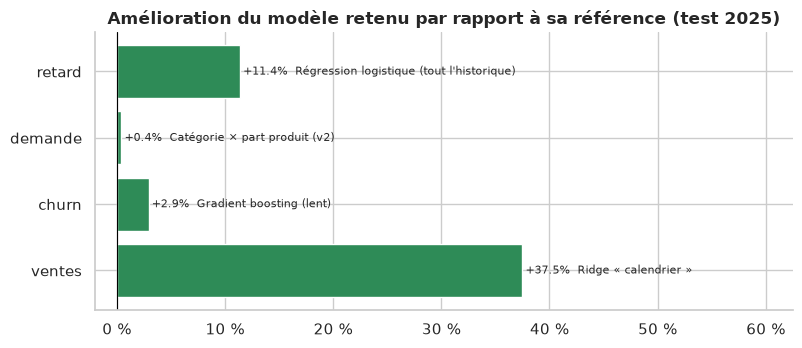

,cas,mesure,sens,reference,valeur_reference,modele_retenu,valeur_retenu,amelioration_relative,statut
0,ventes,MAPE_total,plus bas = mieux,Holt-Winters (référence),0.153,Ridge « calendrier »,0.095,0.375,OK
1,churn,AUC,plus haut = mieux,Règle « récence » (référence),0.794,Gradient boosting (lent),0.818,0.029,OK
2,demande,WAPE_produit_mois,plus bas = mieux,Moyenne de l'année précédente (référence),0.477,Catégorie × part produit (v2),0.475,0.004,OK
3,retard,AUC,plus haut = mieux,Règle transporteur 6 mois (référence),0.728,Régression logistique (tout l'historique),0.811,0.114,OK


In [3]:
MESURE = {"ventes": ("MAPE_total", "bas"), "churn": ("AUC", "haut"), "demande": ("WAPE_produit_mois", "bas"), "retard": ("AUC", "haut")}
REFERENCE = {"ventes": "Holt-Winters (référence)", "churn": "Règle « récence » (référence)",
             "demande": "Moyenne de l'année précédente (référence)", "retard": "Règle transporteur 6 mois (référence)"}
lignes = []
for cas, t in metriques.items():
    mesure, sens = MESURE[cas]
    ret, ref = t[t["retenu"]].iloc[0], t[t["modele"] == REFERENCE[cas]].iloc[0]
    gain = (ref[mesure] - ret[mesure]) / ref[mesure] if sens == "bas" else (ret[mesure] - ref[mesure]) / ref[mesure]
    lignes.append({"cas": cas, "mesure": mesure, "sens": "plus bas = mieux" if sens == "bas" else "plus haut = mieux",
                   "reference": REFERENCE[cas], "valeur_reference": ref[mesure],
                   "modele_retenu": ret["modele"], "valeur_retenu": ret[mesure], "amelioration_relative": gain,
                   "statut": "INFO" if ret["modele"] == REFERENCE[cas] else ("OK" if gain > 0 else "ÉCART")})
synthese = pd.DataFrame(lignes)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(synthese["cas"], synthese["amelioration_relative"], color=[cfg.VERT if g > 0 else cfg.ROUGE for g in synthese["amelioration_relative"]])
for i, (g, r) in enumerate(zip(synthese["amelioration_relative"], synthese["modele_retenu"])):
    ax.text(g + 0.003, i, f"{g:+.1%}  {r}", va="center", fontsize=8)
ax.axvline(0, color="black", lw=0.8); ax.set_title("Amélioration du modèle retenu par rapport à sa référence (test 2025)")
cfg.format_pourcent(ax, "x"); ax.set_xlim(min(0, synthese["amelioration_relative"].min()) - 0.02, synthese["amelioration_relative"].max() + 0.25)
montrer("ML05_1_gains")
synthese

> **Lecture.** Les quatre cas ont un modèle retenu qui fait au moins aussi bien que sa référence sur 2025 : **ventes -37,5 %** d'erreur (MAPE 15,3 % → 9,5 %), **retard +11,4 %** d'AUC (0,728 → 0,811), **churn +2,9 %** d'AUC (0,794 → 0,818) et **demande +0,4 %** (WAPE 47,7 % → 47,5 %, version 2 retenue sur la validation). Chaque choix a été fait sur la validation 2024, avant de regarder le test.

## 2. Robustesse : sur-apprentissage et dérive

- **Sur-apprentissage** : un modèle bien meilleur sur ses données d'apprentissage que sur 2025 a appris des détails qui ne se répètent pas.
- **Validation → test** : si la performance chute entre la validation (2024) et le test (2025), c'est le signe d'une dérive.

In [4]:
robustesse = []
for cas in ["churn", "retard"]:
    for _, r in metriques[cas][metriques[cas]["role"] == "candidat"].iterrows():
        robustesse.append({"cas": cas, "modele": r["modele"], "AUC_apprentissage": r["AUC_apprentissage"],
                           "AUC_validation": r["AUC_validation"], "AUC_test": r["AUC"],
                           "ecart_apprentissage_test": r["AUC_apprentissage"] - r["AUC"], "retenu": r["retenu"]})
robustesse = pd.DataFrame(robustesse)
robustesse["statut"] = np.where(robustesse["ecart_apprentissage_test"] > 0.05, "ÉCART", "OK")
derive = lire_csv("ML01_derive")
resume_derive = derive.groupby(["cas", "niveau"]).size().unstack(fill_value=0)
display(robustesse)
resume_derive

,cas,modele,AUC_apprentissage,AUC_validation,AUC_test,ecart_apprentissage_test,retenu,statut
0,churn,Gradient boosting (lent),0.822,0.822,0.818,0.004,True,OK
1,churn,Régression logistique (C=1),0.807,0.821,0.814,-0.006,False,OK
2,churn,Forêt aléatoire,0.851,0.820,0.816,0.035,False,OK
3,retard,Régression logistique (tout l'historique),0.811,0.729,0.811,-0.000,True,OK
4,retard,Gradient boosting (tout l'historique),0.843,0.711,0.795,0.049,False,OK


niveau,dérive modérée,forte dérive,stable
cas,,,
churn,4,0,27
demande,1,7,12
retard,0,0,16
ventes,0,7,4


> **Lecture.** **Pas de sur-apprentissage** pour les modèles retenus : écart d'AUC entre apprentissage et test de 0,004 (churn) et 0,000 (retard). La forêt aléatoire (0,035) et le boosting du retard (0,049) s'en approchent : c'est une raison de plus de ne pas les retenir. Les dérives sont connues et expliquées : tendance et calendrier pour les ventes et la demande (voulues), allongement de l'historique pour le churn (modérée), **changement de relation** pour le retard (le point à surveiller en production).

## 3. Classeur de comparaison des modèles

In [5]:
import datetime as dt
quand = f"Livrable ML v1.0 du 26/11/2026 · Sarra Abdeljaouad · résultats lus dans 06_Exports/Tables le {dt.datetime.now():%d/%m/%Y à %H:%M}"
fiche = lire_csv("ML01_fiche_jeux_de_donnees")
feuilles = {
    "00_Synthese": ("Comparaison des modèles — TuniShop", quand, synthese),
    "01_Jeux_de_donnees": ("Jeux de données des 4 cas", "Construits par 01_Preparation_Datasets_ML à partir des vues bi du DWH", fiche),
    "02_Ventes": ("Prévision des ventes — CA TTC mensuel par catégorie (test 2025)", "MAPE et WAPE : plus bas = mieux ; biais > 0 = surestimation", metriques["ventes"]),
    "03_Churn": ("Prédiction du churn à 90 jours (test 2025)", "AUC : plus haut = mieux ; seuil choisi sur la validation 2024", metriques["churn"]),
    "04_Demande": ("Prédiction de la demande par produit et par mois (test 2025)", "WAPE : erreur absolue totale / quantité réelle", metriques["demande"]),
    "05_Retard": ("Prédiction du retard de livraison (test 2025)", "AUC : plus haut = mieux ; fenêtre d'apprentissage choisie sur la validation", metriques["retard"]),
    "06_Robustesse": ("Sur-apprentissage", "Écart d'AUC entre apprentissage et test ; ÉCART si > 0,05", robustesse),
    "07_Derive": ("Dérive des variables entre 2023-2024 et 2025 (PSI)", "< 0,10 stable ; 0,10-0,25 modérée ; > 0,25 forte", derive),
}
chemin = cfg.exporter_excel(feuilles, cfg.DOSSIER_LIVRABLES / "Machine_Learning" / "Comparaison_Modeles.xlsx", "Comparaison des modèles — TuniShop")

Classeur enregistré : 04_Livrables\Machine_Learning\Comparaison_Modeles.xlsx


## 4. Recommandations de mise en production

> **Lecture.** | Cas | Modèle en production | Fréquence | Point de vigilance |
|---|---|---|---|
| Prévision des ventes | Ridge « calendrier » | réapprentissage mensuel | ajouter chaque année le calendrier commercial de l'année suivante |
| Churn | gradient boosting | score à chaque fin de trimestre | cibler les déciles 4 à 7 (clients encore récupérables) |
| Demande | version 2 : catégorie × part produit | mensuelle | corriger la croissance (biais de -23,5 %) |
| Retard de livraison | régression logistique | réapprentissage et recalibrage mensuels | alerte si le taux réel d'un transporteur s'écarte du prévu |

**Suivi commun :** recalculer chaque mois le PSI des variables (`validation.derive`) et chaque trimestre la mesure principale de chaque modèle sur les nouvelles données du DWH. Ces notebooks lisant le DWH en direct, ils peuvent être planifiés après le rechargement nocturne de la chaîne (Agent SQL).

In [6]:
print('Évaluation terminée.')

Évaluation terminée.
